# Prédire le nombre de cycles de charge/décharge restants (RUL) d'une batterie lithium-ion, pour décider du moment de son remplacement préventif

**Groupe :** [Prénom NOM1, Prénom NOM2] · **Parcours :** [FISE / FISA] · **Date :** 2026-11-18
**Données :** Battery Remaining Useful Life (RUL) Dataset, Kaggle — [razanihababdellatif/battery-remaining-useful-life-rul-dataset](https://www.kaggle.com/datasets/razanihababdellatif/battery-remaining-useful-life-rul-dataset) · **Type de problème :** régression

---

## Mode d'emploi du gabarit (à supprimer avant le dépôt)

Ce gabarit est la **structure de votre notebook de projet**. Il suit le plan en 13 parties des consignes. Votre notebook est votre **rapport d'ingénieur** : on doit pouvoir le lire de haut en bas comme un document, avec le code, les résultats, leur analyse et la justification de chaque choix.

**Ce qu'il faut reproduire, c'est la démarche, pas les traitements de l'exemple Pima.** Les algorithmes, les variables et les figures dépendent de votre problème.

Chaque étape porte une étiquette :

| Étiquette | Signification |
|---|---|
| **[Indispensable]** | à faire dans tout projet |
| **[Selon le problème]** | à faire si votre problème l'exige : classification, régression, cible à construire, données groupées ou temporelles, volet non supervisé |
| **[Approfondissement]** | utile, valorisé, mais pas exigé |

Chaque étape répond aux mêmes questions :
- **Question :** que cherche-t-on à savoir ?
- **Pourquoi :** à quoi cela sert-il pour la suite ?
- **Comment :** quelle méthode employer ?
- **À présenter :** quels résultats montrer ?
- **Interpréter et décider :** comment lire ces résultats, et quelle décision en tirer ?
- **Limites :** que ne permet-on pas de conclure ?

Un **exemple de rédaction** montre le niveau attendu. Les exemples sont **fictifs**, pris dans des domaines variés, et leurs chiffres sont illustratifs : ne les recopiez pas, imitez leur construction.

**Présenter chaque résultat en quatre temps.** Sous chaque figure ou tableau important, écrivez :
1. **Observation :** ce que l'on voit, chiffré.
2. **Interprétation :** comment l'expliquer, et quelles hypothèses restent ouvertes.
3. **Décision :** quelle conséquence pour la suite du projet.
4. **Limite :** ce que ce résultat ne permet pas de conclure.

**Le code** est générique et a été testé sur les trois structures de données (lignes indépendantes, données groupées, séries temporelles) et sur les trois types de problèmes. Il tourne d'abord sur le jeu Pima, à titre de démonstration. Pour votre projet :
1. modifiez la cellule **Configuration** ;
2. relancez tout (*Run All*) ;
3. adaptez les cellules marquées `# TODO` ;
4. remplacez les textes entre crochets par **votre** analyse.

Le notebook de référence `Pima_trois_etudes.ipynb` montre un projet complet rédigé de cette façon.

## Résumé (à écrire en dernier)

| Question posée | Résultat principal (test, avec intervalle de confiance) | Décision recommandée | Principale limite |
|---|---|---|---|
| … | … | … | … |

## 0. Configuration et outils **[Indispensable]**

La cellule ci-dessous est **la cellule principale à modifier** pour faire tourner le gabarit sur vos données. Vous adapterez ensuite les cellules marquées `# TODO` (règle métier, familles de modèles, choix du modèle et de k…).

| Paramètre | Valeurs possibles | Comment choisir |
|---|---|---|
| `FICHIER` | chemin relatif | vos données, dans le dossier `data/` |
| `CIBLE` | nom de colonne, ou `None` | la grandeur à prédire (partie 1) ; `None` pour un projet entièrement non supervisé |
| `CODES_MANQUANTS` | dictionnaire | codes qui signifient « manquant », constatés au contrôle qualité |
| `PART_TEST` | 0,2 en général | part réservée au test : lignes, groupes ou période finale |
| `TYPE_PROBLEME` | `"classification"`, `"regression"`, `"non_supervise"` | selon la nature de la cible (partie 1) |
| `STRUCTURE` | `"independantes"`, `"groupes"`, `"temporelle"` | selon l'unité indépendante (partie 2) |
| `COLONNE_GROUPE`, `COLONNE_TEMPS`, `HORIZON` | noms de colonnes, nombre de lignes | seulement pour des données groupées ou temporelles ; `HORIZON` ne sert qu'en `"temporelle"` |
| `VARIABLES_EXCLUES` | liste de colonnes | variables non disponibles à l'instant de décision (partie 2) |
| `COUT_FN`, `COUT_FP` | nombres | hypothèse de coût de la partie 1 (classification) |

In [1]:
# =============================================================================
# CONFIGURATION DU PROJET — la seule cellule à adapter avant de lancer le reste
# =============================================================================
FICHIER = "battery_observations.csv"   # mesures par cycle ; jointes à battery_metadata.csv dans le contrôle qualité (partie 2)
CIBLE = "remaining_useful_cycles"       # nombre de cycles de charge/décharge restants avant la fin de vie de la batterie
TYPE_PROBLEME = "regression"            # "classification" | "regression" | "non_supervise"
STRUCTURE = "groupes"                   # plusieurs cycles par batterie : l'unité indépendante est la batterie, pas le cycle
COLONNE_GROUPE = "battery_id"           # identifiant de la batterie
COLONNE_TEMPS = None                    # pas de structure temporelle ici (voir partie 2) : le découpage par groupe suffit à éviter la fuite
HORIZON = 0                             # non utilisé (STRUCTURE != "temporelle")
VARIABLES_EXCLUES = [
    "eol_reached",           # connu seulement après coup (la batterie a-t-elle fini par tomber en panne) : jamais disponible pour une batterie en service
    "remaining_useful_efc",  # la cible elle-même, exprimée dans une autre unité (cycles équivalents pleins) : fuite directe
    "dataset_split",         # partition d'origine attribuée par les auteurs du jeu de données, pas une variable physique ; nous refaisons notre propre découpage
    "timestamp",             # horodatage brut du cycle, redondant avec cycle_index/battery_age_days, sans valeur ajoutée en tant que texte
]
CODES_MANQUANTS = {}                    # aucun zéro suspect ici (vérifié en partie 2) ; les vraies valeurs manquantes (pack_temp_c, cible censurée) sont déjà en NaN
COUT_FN, COUT_FP = 5, 1                 # non utilisés : hypothèse de coût réservée à la classification (voir partie 1)
PART_TEST = 0.2                         # part des groupes (batteries) réservée au test
SEED = 42
# Les valeurs ci-dessus font tourner le gabarit sur le jeu battery_rul (projet noté), et non plus sur la démonstration Pima.
if HORIZON and STRUCTURE != "temporelle":
    print("Remarque : HORIZON n'est utilisé qu'avec STRUCTURE = 'temporelle'. Avec des groupes (enregistrements séparés), "
          "la cible construite dans chaque groupe ne déborde pas sur un autre : aucun écart n'est nécessaire.")


In [2]:
import os, time, platform, warnings
# Avertissements attendus quand un pli interne ne contient qu'une classe (cas géré : score ignoré).
# Les filtres doivent aussi s'appliquer aux processus de calcul parallèle, d'où la variable d'environnement.
_FILTRES = ["Scoring failed", "One or more of the test scores are non-finite", "No positive class found"]
os.environ["PYTHONWARNINGS"] = ",".join(f"ignore:{m}:UserWarning" for m in _FILTRES)
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import (train_test_split, KFold, StratifiedKFold, GroupKFold,
                                     StratifiedGroupKFold, GroupShuffleSplit, TimeSeriesSplit,
                                     GridSearchCV)
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.inspection import permutation_importance
from sklearn.metrics import (average_precision_score, roc_auc_score, brier_score_loss, confusion_matrix,
                             precision_recall_curve, mean_absolute_error, mean_squared_error, r2_score,
                             silhouette_score, davies_bouldin_score, adjusted_rand_score)

from sklearn.exceptions import FitFailedWarning
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=FitFailedWarning)   # réglages internes impossibles (pli à une seule classe) : ignorés
for _m in _FILTRES:
    warnings.filterwarnings("ignore", message=_m, category=UserWarning)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
SUPERVISE = TYPE_PROBLEME in ("classification", "regression")
T_DEBUT = time.time()
print(f"Python {platform.python_version()} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}")
print(f"Problème : {TYPE_PROBLEME} | structure des données : {STRUCTURE}")

Python 3.13.12 | pandas 3.0.6 | scikit-learn 1.9.1
Problème : regression | structure des données : groupes


La cellule suivante définit les **outils génériques** : découpages adaptés à la structure, validation croisée imbriquée, prédictions hors pli, intervalles de confiance, choix du seuil, construction d'une cible future. Lisez-la une fois pour comprendre ce qu'elle fait, mais ne la modifiez pas.

In [3]:
# =============================================================================
# OUTILS GÉNÉRIQUES — à lire une fois, sans les modifier
# =============================================================================
def cv_pour(structure, type_probleme, n=5, graine=SEED):
    """Validation croisée adaptée à la structure des données (plis jamais mélangés entre unités)."""
    if structure == "temporelle":
        # le pli de validation est toujours postérieur ; `gap` écarte les lignes dont la cible chevauche la validation
        return TimeSeriesSplit(n_splits=n, gap=HORIZON)
    if structure == "groupes":
        return (StratifiedGroupKFold(n_splits=n, shuffle=True, random_state=graine)
                if type_probleme == "classification" else GroupKFold(n_splits=n))
    return (StratifiedKFold(n_splits=n, shuffle=True, random_state=graine)
            if type_probleme == "classification" else KFold(n_splits=n, shuffle=True, random_state=graine))

def evaluer_imbrique(pipe, grille, X, y, groupes, scorers, scoring_reglage):
    """Validation croisée imbriquée écrite explicitement, valable pour les trois structures.
    Boucle interne : GridSearchCV règle les hyperparamètres sur le train du pli (groupes transmis).
    Boucle externe : le modèle réglé est évalué sur un pli jamais vu.
    Renvoie un DataFrame (un pli par ligne, une colonne par métrique)."""
    cv_ext = cv_pour(STRUCTURE, TYPE_PROBLEME, graine=SEED + 1)
    lignes = []
    for tr, va in cv_ext.split(X, y, groupes):
        if pli_inutilisable(y.iloc[tr], y.iloc[va]):
            continue
        rech = GridSearchCV(clone(pipe), grille, cv=cv_pour(STRUCTURE, TYPE_PROBLEME), scoring=scoring_reglage,
                            n_jobs=-1, error_score=np.nan)
        rech.fit(X.iloc[tr], y.iloc[tr], **({"groups": groupes.iloc[tr]} if groupes is not None else {}))
        lignes.append({nom: f(rech, X.iloc[va], y.iloc[va]) for nom, f in scorers.items()})
    return pd.DataFrame(lignes)

def pli_inutilisable(y_tr, y_va):
    """En classification, un pli dont le train ou la validation ne contient qu'une classe est ignoré (et signalé).
    Cela arrive surtout en temporel, quand les événements sont rares ou regroupés dans le temps.
    Si beaucoup de plis sont ignorés, réduisez le nombre de plis ou allongez la période étudiée."""
    if TYPE_PROBLEME == "classification" and (y_tr.nunique() < 2 or y_va.nunique() < 2):
        print(f"  pli ignoré : une seule classe (train : {y_tr.nunique()}, validation : {y_va.nunique()})")
        return True
    return False

def predictions_hors_pli(pipe, grille, X, y, groupes, scoring_reglage, proba=True):
    """Prédiction de chaque ligne du train par un modèle (réglé dans le pli) qui ne l'a pas vue.
    En temporel, les premières lignes ne sont jamais prédites : elles valent NaN."""
    cv_ext = cv_pour(STRUCTURE, TYPE_PROBLEME, graine=SEED + 1)
    pred = pd.Series(np.nan, index=X.index)
    for tr, va in cv_ext.split(X, y, groupes):
        if pli_inutilisable(y.iloc[tr], y.iloc[va]):
            continue
        rech = GridSearchCV(clone(pipe), grille, cv=cv_pour(STRUCTURE, TYPE_PROBLEME), scoring=scoring_reglage,
                            n_jobs=-1, error_score=np.nan)
        rech.fit(X.iloc[tr], y.iloc[tr], **({"groups": groupes.iloc[tr]} if groupes is not None else {}))
        pred.iloc[va] = rech.predict_proba(X.iloc[va])[:, 1] if proba else rech.predict(X.iloc[va])
    return pred

def ic_bootstrap(y_vrai, y_score, metrique, groupes=None, temporel=False, n=1000, graine=SEED):
    """Intervalle de confiance à 95 % d'une métrique sur le test, par bootstrap adapté à la structure :
    lignes indépendantes -> on tire des lignes ; groupes -> on tire des groupes entiers ;
    temporel -> on tire des blocs consécutifs (bootstrap par blocs mobiles)."""
    rng = np.random.default_rng(graine)
    y_vrai, y_score = np.asarray(y_vrai), np.asarray(y_score)
    m = len(y_vrai)
    if groupes is not None:
        groupes = np.asarray(groupes); uniques = np.unique(groupes)
        index_par_groupe = {g: np.where(groupes == g)[0] for g in uniques}
    longueur_bloc = max(1, m // 20)
    valeurs = []
    for _ in range(n):
        if groupes is not None:
            idx = np.concatenate([index_par_groupe[g] for g in rng.choice(uniques, len(uniques))])
        elif temporel:
            debuts = rng.integers(0, m - longueur_bloc + 1, int(np.ceil(m / longueur_bloc)))
            idx = np.concatenate([np.arange(d, d + longueur_bloc) for d in debuts])[:m]
        else:
            idx = rng.integers(0, m, m)
        try:
            valeurs.append(metrique(y_vrai[idx], y_score[idx]))
        except ValueError:          # tirage sans aucun positif, par exemple : on l'ignore
            pass
    return np.percentile(valeurs, [2.5, 97.5])

def table_seuils(y, proba, cout_fn=COUT_FN, cout_fp=COUT_FP, seuils=np.round(np.arange(0.02, 0.99, 0.01), 2)):
    """Classification : matrice de confusion, rappel, précision, part prédite positive et coût par seuil."""
    lignes = []
    for s in seuils:
        vn, fp, fn, vp = confusion_matrix(y, (proba >= s).astype(int), labels=[0, 1]).ravel()
        lignes.append({"seuil": s, "VP": vp, "FP": fp, "FN": fn, "VN": vn,
                       "rappel": vp / (vp + fn) if vp + fn else np.nan,
                       "précision": vp / (vp + fp) if vp + fp else np.nan,
                       "part prédite positive": (vp + fp) / len(y), "coût": cout_fn * fn + cout_fp * fp})
    return pd.DataFrame(lignes).set_index("seuil")

def cible_a_horizon(df, colonne, horizon, groupe=None):
    """Construit une cible FUTURE : la valeur de `colonne` `horizon` pas de temps plus tard
    (dans le même groupe s'il y en a un). Les dernières lignes, sans futur connu, valent NaN.
    Les variables explicatives, elles, ne doivent utiliser que le présent et le passé."""
    if groupe is None:
        return df[colonne].shift(-horizon)
    return df.groupby(groupe)[colonne].shift(-horizon)

## 1. En-tête et contexte **[Indispensable]**

**Question :** quel problème d'ingénieur traite-t-on, et quelle décision le modèle doit-il éclairer ?
**Pourquoi :** sans décision ni instant de décision, on ne peut choisir ni les variables autorisées, ni la métrique, ni le seuil.
**Comment :** remplissez le tableau, puis rédigez le cadrage.

| Question (une phrase) | Cible | Décision éclairée | Instant de décision | Erreur la plus coûteuse |
|---|---|---|---|---|
| Combien de cycles de charge/décharge reste-t-il à une batterie avant sa fin de vie ? | `remaining_useful_cycles` | Décider du moment de remplacement préventif d'une batterie (planification de la maintenance et du stock de pièces) | À chaque nouveau cycle observé, à partir des mesures de ce cycle et des cycles précédents de la même batterie | Sur-estimer le RUL restant : risque de panne avant le remplacement planifié |

**Hypothèse de coût :** le jeu de données ne fournit aucune table de coûts réels (il est synthétique) : nous ne construisons pas d'hypothèse `COUT_FN`/`COUT_FP` chiffrée comme en classification, ces paramètres ne s'appliquant qu'à ce cas. L'asymétrie « sur-estimer est pire que sous-estimer » est traitée qualitativement en partie 7, par le signe des résidus, plutôt que par un seuil de coût. · **Métrique principale, et pourquoi :** **MAE** (erreur absolue moyenne, en nombre de cycles) : elle s'interprète directement dans l'unité métier et pondère les erreurs linéairement ; le **RMSE** est donné en complément, car il pénalise davantage les grosses erreurs — pertinent vu le coût asymétrique d'une sur-estimation importante. · **Fiche sujet validée :** cadrage repris sans changement de la fiche sujet validée en séance de TP (dataset, cible, unité indépendante, métrique).

> **Exemple de rédaction (fictif : surveillance d'un banc moteur).**
> « Le banc d'essai enregistre en continu les vibrations d'un moteur électrique. Nous cherchons à **signaler, au moment où une fenêtre de 10 s vient d'être acquise, si un défaut de roulement est présent**, afin de décider d'arrêter ou non l'essai pour inspection. L'erreur la plus coûteuse est le défaut non détecté : il peut détruire le banc. Une inspection inutile ne coûte qu'une heure d'arrêt. Faute de données de coût réelles, nous retenons l'hypothèse qu'un défaut manqué coûte dix fois une inspection inutile. Nous la discuterons en partie 10. La classe « défaut » ne représente que 8 % des fenêtres : l'*accuracy* serait trompeuse (un modèle qui ne détecte jamais rien atteindrait 92 %). Nous retenons donc l'*average precision* comme métrique de comparaison, puis, au seuil choisi, le rappel et le coût total. »

> **Vérifications.** ☐ La décision et son instant sont explicites. ☐ L'hypothèse de coût est chiffrée et présentée comme une hypothèse. ☐ La métrique est choisie avant tout entraînement.

## 2. Données et éthique **[Indispensable]**

**Question :** d'où viennent les données, que mesure chaque variable, et laquelle a le droit d'entrer dans le modèle ?
**Pourquoi :** c'est ici que naissent la plupart des fuites de données. Une variable connue *après* la décision donne un modèle brillant sur le papier et inutilisable en pratique.
**Comment :** dictionnaire des variables, test de l'instant de décision pour chacune, puis identification de l'unité indépendante.

**Source :** Kaggle, [razanihababdellatif/battery-remaining-useful-life-rul-dataset](https://www.kaggle.com/datasets/razanihababdellatif/battery-remaining-useful-life-rul-dataset) · **Licence :** CC0 (domaine public) · **Taille :** 200 batteries, 172 779 cycles au total (≈34 500 après le sous-échantillonnage décrit au contrôle qualité) · **Acquisition :** jeu **synthétique**, généré explicitement pour imiter les courbes de dégradation de batteries lithium-ion réelles tout en garantissant la confidentialité des données (description officielle du jeu de données) — il n'y a pas de capteurs physiques réels derrière ces mesures.
**Comment la cible a été obtenue :** `remaining_useful_cycles` est calculée par les auteurs du jeu comme le nombre de cycles restants avant la fin de vie simulée de chaque batterie. Elle est volontairement laissée manquante (`NaN`) sur les batteries encore « en service » à la fin de la fenêtre de simulation (29 batteries sur 200), pour imiter la censure d'un parc réel en exploitation ; ces lignes sont retirées automatiquement par le `dropna` de la partie « Réserver le test ».

| Variable | Signification | Unité | Connue à l'instant de décision ? |
|---|---|---|---|
| `cycle_index` | numéro du cycle courant de la batterie | cycles | oui |
| `battery_age_days` | âge de la batterie depuis sa mise en service | jours | oui |
| `time_since_previous_cycle_hours` | temps écoulé depuis le cycle précédent | heures | oui |
| `equivalent_full_cycles` | cycles équivalents pleins cumulés | cycles | oui |
| `soc_start_pct` / `soc_end_pct` | état de charge en début / fin de cycle | % | oui |
| `depth_of_discharge_pct` | profondeur de décharge du cycle | % | oui |
| `high_soc_exposure_fraction` / `low_soc_exposure_fraction` | fraction du cycle passée à un état de charge extrême | fraction | oui |
| `charge_c_rate` / `discharge_c_rate` | régime de charge / décharge | C | oui |
| `charge_current_a` / `discharge_current_a` | courant de charge / décharge | A | oui |
| `charge_duration_min` / `discharge_duration_min` | durée de charge / décharge | min | oui |
| `energy_discharged_kwh` | énergie déchargée pendant le cycle | kWh | oui |
| `ambient_temp_c` / `pack_temp_c` | température ambiante / du pack | °C | oui |
| `cumulative_high_temp_hours` | heures cumulées passées à haute température | heures | oui |
| `cooling_active` | refroidissement actif pendant le cycle | binaire | oui |
| `pack_voltage_mean_v`, `pack_voltage_charge_v`, `pack_voltage_discharge_v` | tensions du pack | V | oui |
| `state_of_health_pct` | état de santé actuel (capacité restante / capacité initiale) | % | oui |
| `internal_resistance_mOhm` | résistance interne mesurée au cycle courant | mΩ | oui |
| `degradation_status` | statut de dégradation courant (catégorie dérivée du SoH actuel) | catégorie | oui |
| `chemistry`, `manufacturer`, `climate_zone`, `usage_strategy`, `nominal_capacity_kwh` | métadonnées statiques de la batterie (jointes depuis `battery_metadata.csv`) | — | oui |
| `eol_reached` | la batterie a-t-elle fini par atteindre sa fin de vie dans la fenêtre d'observation | booléen | **non → `VARIABLES_EXCLUES`** (connu seulement rétrospectivement, jamais pour une batterie en service) |
| `remaining_useful_efc` | RUL exprimé en cycles équivalents pleins | cycles | **non → `VARIABLES_EXCLUES`** (reformulation directe de la cible, fuite) |
| `dataset_split` | partition train/validation/test attribuée par les auteurs du jeu | — | **non → `VARIABLES_EXCLUES`** (pas une variable physique ; nous refaisons notre propre découpage) |
| `timestamp` | horodatage brut du cycle | date | **non → `VARIABLES_EXCLUES`** (texte redondant avec `cycle_index`/`battery_age_days`) |
| `battery_id` | identifiant de la batterie | — | utilisé comme `COLONNE_GROUPE`, pas comme variable du modèle |

**Unité indépendante et structure** (paramètre `STRUCTURE`) :

| Situation | Exemple | `STRUCTURE` | Conséquence |
|---|---|---|---|
| chaque ligne est indépendante | une pièce, un client, un patient | `"independantes"` | découpage aléatoire, stratifié en classification |
| **plusieurs lignes par unité (retenu ici)** | fenêtres d'un même essai, d'un même trajet, d'une même machine — ici, les cycles d'une même batterie | **`"groupes"`** | les unités entières vont soit dans le train, soit dans le test |
| l'ordre du temps compte | prévision, dérive, usure | `"temporelle"` | le test est la période la plus récente ; jamais de futur dans le train |

Une batterie produit plusieurs centaines de cycles consécutifs, très corrélés entre eux (même chimie, même historique d'usage, dégradation progressive) : une ligne n'est **pas** une unité indépendante. Le modèle doit fonctionner sur des **batteries jamais vues** en production, donc toutes les lignes d'une même `battery_id` vont du même côté du découpage (`STRUCTURE = "groupes"`, `COLONNE_GROUPE = "battery_id"`).

**Éthique et confidentialité :** le jeu est **explicitement synthétique** (généré pour la recherche et les compétitions de machine learning, sans donnée personnelle ni confidentialité d'entreprise à protéger) : pas d'enjeu RGPD. La limite principale est que les régularités apprises ici ne sont pas garanties de se transférer à de vraies batteries lithium-ion — nous le rappelons en partie 10 (domaine de validité).

> **Exemple de rédaction (fictif : consommation énergétique de bâtiments).**
> « Les 52 000 lignes correspondent à des relevés horaires de 30 bâtiments sur deux ans. Une ligne n'est donc **pas** une unité indépendante : deux heures consécutives d'un même bâtiment se ressemblent beaucoup plus que deux bâtiments différents. Comme le modèle doit servir à prévoir la consommation de **nouveaux** bâtiments, nous découpons par bâtiment : 6 bâtiments entiers sont réservés au test. La variable `consommation_veille` est connue au moment de la prévision, nous la gardons. La variable `facture_mensuelle` est établie après coup, à partir de la cible : nous l'excluons. »

> **Vérifications.** ☐ Chaque variable a passé le test de l'instant de décision. ☐ L'unité indépendante est identifiée et justifie `STRUCTURE`. ☐ Apprentis : accord écrit et anonymisation.

### Contrôle qualité **[Indispensable]**

**Question :** le fichier est-il sain ?
**Comment :** types, doublons, valeurs manquantes, codes de manque déguisés, plages physiques. Pour des capteurs, cherchez aussi les saturations, les valeurs figées et les ruptures d'échantillonnage. On ne regarde **pas** encore le lien avec la cible.

In [4]:
obs = pd.read_csv(FICHIER)
meta = pd.read_csv("battery_metadata.csv")
# Un cycle sur 5 par batterie : cycles consécutifs très corrélés (presque les mêmes mesures) + coût de calcul sur 172 779 lignes
obs = obs[obs["cycle_index"] % 5 == 0].reset_index(drop=True)
df = obs.merge(meta, on="battery_id", how="left")
for col, codes in CODES_MANQUANTS.items():
    df[col] = df[col].replace(codes, np.nan)
if STRUCTURE == "temporelle":
    df = df.sort_values(COLONNE_TEMPS).reset_index(drop=True)
print("dimensions :", df.shape, "| doublons exacts :", df.duplicated().sum())
if STRUCTURE == "groupes":
    taille = df.groupby(COLONNE_GROUPE).size()
    print(f"{taille.size} groupes ; lignes par groupe : min {taille.min()}, médiane {taille.median():.0f}, max {taille.max()}")
manquants = df.isna().mean().mul(100).round(1)
print("valeurs manquantes (%) :", manquants[manquants > 0].to_dict())
df.describe().T


dimensions : (34485, 37) | doublons exacts : 0
200 groupes ; lignes par groupe : min 19, médiane 177, max 300
valeurs manquantes (%) : {'pack_temp_c': 1.0, 'remaining_useful_cycles': 25.1, 'remaining_useful_efc': 25.1}


,count,mean,std,min,25%,50%,75%,max
cycle_index,34485.0,524.823836,369.302510,5.000000,220.000,455.000,775.000,1500.000
battery_age_days,34485.0,893.928992,647.731773,3.800000,367.000,749.900,1324.900,2688.200
time_since_previous_cycle_hours,34485.0,40.631434,17.405797,12.000000,25.500,39.500,55.800,72.000
equivalent_full_cycles,34485.0,204.294914,131.416657,1.100000,92.960,187.940,306.360,594.040
soc_start_pct,34485.0,78.062453,10.826354,35.800000,70.600,78.700,86.300,100.000
soc_end_pct,34485.0,36.785043,15.461894,5.000000,25.500,36.500,47.500,92.600
depth_of_discharge_pct,34485.0,41.277199,15.697269,5.000000,29.700,40.100,51.900,94.600
high_soc_exposure_fraction,34485.0,0.084864,0.141379,0.000000,0.000,0.000,0.137,1.000
low_soc_exposure_fraction,34485.0,0.015707,0.045577,0.000000,0.000,0.000,0.000,0.404
charge_c_rate,34485.0,0.639799,0.407655,0.120000,0.370,0.550,0.730,2.500


> **À rédiger sous ce résultat (en quatre temps).**
>
> **Observation.** 34 485 lignes après sous-échantillonnage (1 cycle sur 5 parmi 172 779), 0 doublon exact, 200 batteries de 19 à 300 lignes chacune (médiane 177). Seules `pack_temp_c` (1,0 % de NaN) et la cible `remaining_useful_cycles`/`remaining_useful_efc` (25,1 % de NaN) comportent de vraies valeurs manquantes. **Interprétation.** Le taux très faible sur `pack_temp_c` est cohérent avec un capteur fiable (pas de zéros suspects comme au Pima) ; les 25,1 % de cible manquante correspondent exactement à la censure documentée par les auteurs (29/200 batteries encore « en service » à la fin de la simulation). **Décision.** `pack_temp_c` sera imputé par la médiane dans le pipeline (partie 4) ; les lignes à cible manquante sont retirées automatiquement pour l'apprentissage supervisé (partie « Réserver le test »). **Limite.** Écarter les batteries censurées introduit un biais de sélection potentiel : le modèle n'apprendra que sur des batteries ayant effectivement atteint leur fin de vie pendant la fenêtre d'observation (repris en partie 10).

> *Exemple :* « **Observation.** 2 % des relevés de pression valent exactement 0 bar, alors que le circuit est toujours pressurisé en fonctionnement. **Interprétation.** Il s'agit vraisemblablement de pertes de communication du capteur, et non de mesures. **Décision.** Les zéros de pression sont codés comme valeurs manquantes (`CODES_MANQUANTS`). **Limite.** Si certains zéros étaient réels, par exemple à l'arrêt, nous les perdons. Nous vérifierons en exploration qu'ils ne coïncident pas avec les phases d'arrêt. »

### Construire la cible **[Selon le problème]**

**Non applicable ici :** `remaining_useful_cycles` existe déjà telle quelle dans `battery_observations.csv`, calculée par les auteurs du jeu — rien à construire. Le seul point de vigilance analogue est déjà traité au contrôle qualité : les cycles des 29 batteries censurées (cible = `NaN`) sont automatiquement retirés par le `dropna` de la cellule « Réserver le test » ci-dessous, faute de label connu.

À faire **si la cible n'existe pas telle quelle** : événement à venir, seuil à appliquer, étiquette dérivée d'une mesure. Cette étape vient après le chargement (et, en temporel, après le tri chronologique fait par la cellule précédente), et avant le découpage.

**Les trois règles :**
1. La règle de construction est fixée **a priori** et justifiée : seuil métier, norme, horizon d'usage. Elle ne s'ajuste pas pour améliorer le score.
2. **Si la cible est future** (dans h pas de temps), les variables explicatives ne doivent utiliser **que le présent et le passé** : moyennes glissantes passées, valeurs retardées. Deux cas :
   - **plusieurs enregistrements** (essais, trajets, machines) : construisez la cible **dans chaque enregistrement** (`groupe=`) et choisissez `STRUCTURE = "groupes"`. Les enregistrements entiers étant séparés entre train et test, aucune cible ne déborde sur l'autre côté ;
   - **un seul enregistrement continu** : choisissez `STRUCTURE = "temporelle"` et renseignez `HORIZON = h`, **en nombre de lignes** (données triées, à pas régulier). Le gabarit écarte alors les h lignes dont la cible chevauche la période suivante.
3. Toute colonne qui a servi à construire la cible (par exemple la valeur future elle-même) va dans `VARIABLES_EXCLUES`.

> **Exemple de rédaction (fictif : prévision d'une surchauffe).**
> « Il n'existe pas de colonne "surchauffe". Nous la construisons ainsi : il y a surchauffe si la température mesurée **5 minutes plus tard** (300 pas à 1 Hz) dépasse 85 °C, seuil d'alarme fixé par le constructeur. Les variables explicatives sont la température actuelle, sa moyenne sur les 60 dernières secondes et le courant moteur : toutes sont connues au moment de décider. La température future, qui a servi à définir la cible, est exclue des variables. Les 300 dernières lignes de chaque enregistrement n'ont pas de futur connu : elles sont retirées. »

In [5]:
# Non applicable : remaining_useful_cycles existe déjà dans battery_observations.csv (voir note ci-dessus).

### Réserver le test **[Indispensable]**

**Pourquoi :** le test simule des données jamais vues. S'il influence un seul choix, la performance annoncée devient optimiste.
**Comment :** la cellule applique automatiquement le découpage adapté à `STRUCTURE`, et **vérifie** qu'aucun groupe ni aucune période ne se retrouve des deux côtés.

In [6]:
# =============================================================================
# RÉSERVER LE TEST — une seule fois, au début, selon la structure des données
# =============================================================================
if CIBLE is not None:
    df = df.dropna(subset=[CIBLE])           # on n'impute jamais une cible
colonnes_hors_modele = [c for c in [CIBLE, COLONNE_GROUPE, COLONNE_TEMPS] + VARIABLES_EXCLUES if c is not None]
VARIABLES = [c for c in df.columns if c not in colonnes_hors_modele]
X = df[VARIABLES]
y = df[CIBLE] if CIBLE is not None else pd.Series(0, index=df.index)
groupes = df[COLONNE_GROUPE] if STRUCTURE == "groupes" else None

if STRUCTURE == "independantes":
    strat = y if TYPE_PROBLEME == "classification" else None
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=PART_TEST, stratify=strat, random_state=SEED)
    g_train = g_test = None
elif STRUCTURE == "groupes":
    tr, te = next(GroupShuffleSplit(n_splits=1, test_size=PART_TEST, random_state=SEED).split(X, y, groupes))
    X_train, X_test, y_train, y_test = X.iloc[tr], X.iloc[te], y.iloc[tr], y.iloc[te]
    g_train, g_test = groupes.iloc[tr], groupes.iloc[te]
    assert set(g_train).isdisjoint(g_test), "un groupe est à la fois dans le train et dans le test !"
else:   # temporelle : le test est la période la plus récente
    coupure = int((1 - PART_TEST) * len(df))
    fin_train = coupure - HORIZON      # les HORIZON dernières lignes du train auraient une cible située dans le test
    X_train, X_test, y_train, y_test = X.iloc[:fin_train], X.iloc[coupure:], y.iloc[:fin_train], y.iloc[coupure:]
    g_train = g_test = None
    assert df[COLONNE_TEMPS].iloc[:fin_train].max() < df[COLONNE_TEMPS].iloc[coupure:].min()

print(f"variables du modèle ({len(VARIABLES)}) :", VARIABLES)
print(f"train : {X_train.shape} | test : {X_test.shape}")
if TYPE_PROBLEME == "classification":
    print(f"part de positifs : train {y_train.mean():.3f} | test {y_test.mean():.3f}")
# À partir d'ici, X_test et y_test restent FERMÉS jusqu'à la partie 8.

variables du modèle (31) : ['cycle_index', 'battery_age_days', 'time_since_previous_cycle_hours', 'equivalent_full_cycles', 'soc_start_pct', 'soc_end_pct', 'depth_of_discharge_pct', 'high_soc_exposure_fraction', 'low_soc_exposure_fraction', 'charge_c_rate', 'discharge_c_rate', 'charge_current_a', 'discharge_current_a', 'charge_duration_min', 'discharge_duration_min', 'energy_discharged_kwh', 'ambient_temp_c', 'pack_temp_c', 'cumulative_high_temp_hours', 'cooling_active', 'pack_voltage_mean_v', 'pack_voltage_charge_v', 'pack_voltage_discharge_v', 'state_of_health_pct', 'degradation_status', 'internal_resistance_mOhm', 'chemistry', 'manufacturer', 'climate_zone', 'nominal_capacity_kwh', 'usage_strategy']
train : (20568, 31) | test : (5270, 31)


**Résultat réel.** 31 variables retenues pour le modèle. Après suppression des 29 batteries censurées (cible manquante), 171 batteries restent labellisées : le découpage par groupe en réserve 35 (5 270 lignes) pour le test et en garde 136 (20 568 lignes) pour le train, sans aucun `battery_id` commun entre les deux.

> **Exemple de rédaction (fictif : essais de fatigue).** « Les 4 800 fenêtres proviennent de 24 essais de fatigue, chacun sur une éprouvette différente. Des fenêtres d'un même essai partagent l'éprouvette, son montage et les conditions du jour : si on les répartissait au hasard, le modèle serait testé sur des essais qu'il a déjà vus. Nous réservons donc **5 essais entiers** au test (1 000 fenêtres), et la validation croisée se fait elle aussi par essai. Le test ne sera ouvert qu'une fois, en partie 8. »

## 3. Exploration (EDA), sur le train seulement **[Indispensable]**

**Question :** que nous apprennent les données sur la cible et les variables, et qu'en déduire pour le prétraitement ?
**Pourquoi :** chaque choix de prétraitement doit s'appuyer sur un constat.
**Comment :** trois à six figures ou tableaux choisis, **tous calculés sur le train**. La cellule ci-dessous fournit un point de départ. Gardez seulement ce qui mène à une décision, et complétez avec vos propres figures.

**Une figure de rapport :**
- a un **titre qui dit ce qu'elle montre** ;
- a des axes avec leurs **unités** ;
- indique les **effectifs** ;
- a une légende si elle compare des groupes ;
- est **commentée** en quatre temps juste en dessous.

Une figure non commentée n'a pas sa place dans le rapport.

corrélation de Spearman (valeur absolue) avec la cible :
state_of_health_pct                0.86
equivalent_full_cycles             0.62
cycle_index                        0.56
battery_age_days                   0.55
discharge_duration_min             0.23
charge_duration_min                0.18
ambient_temp_c                     0.13
discharge_c_rate                   0.13
pack_temp_c                        0.13
discharge_current_a                0.13
internal_resistance_mOhm           0.13
energy_discharged_kwh              0.11
charge_c_rate                      0.11
charge_current_a                   0.11
depth_of_discharge_pct             0.11
soc_start_pct                      0.10
high_soc_exposure_fraction         0.08
cumulative_high_temp_hours         0.07
soc_end_pct                        0.05
pack_voltage_charge_v              0.05
low_soc_exposure_fraction          0.04
pack_voltage_discharge_v           0.03
time_since_previous_cycle_hours    0.02
pack_voltage_mean_v    

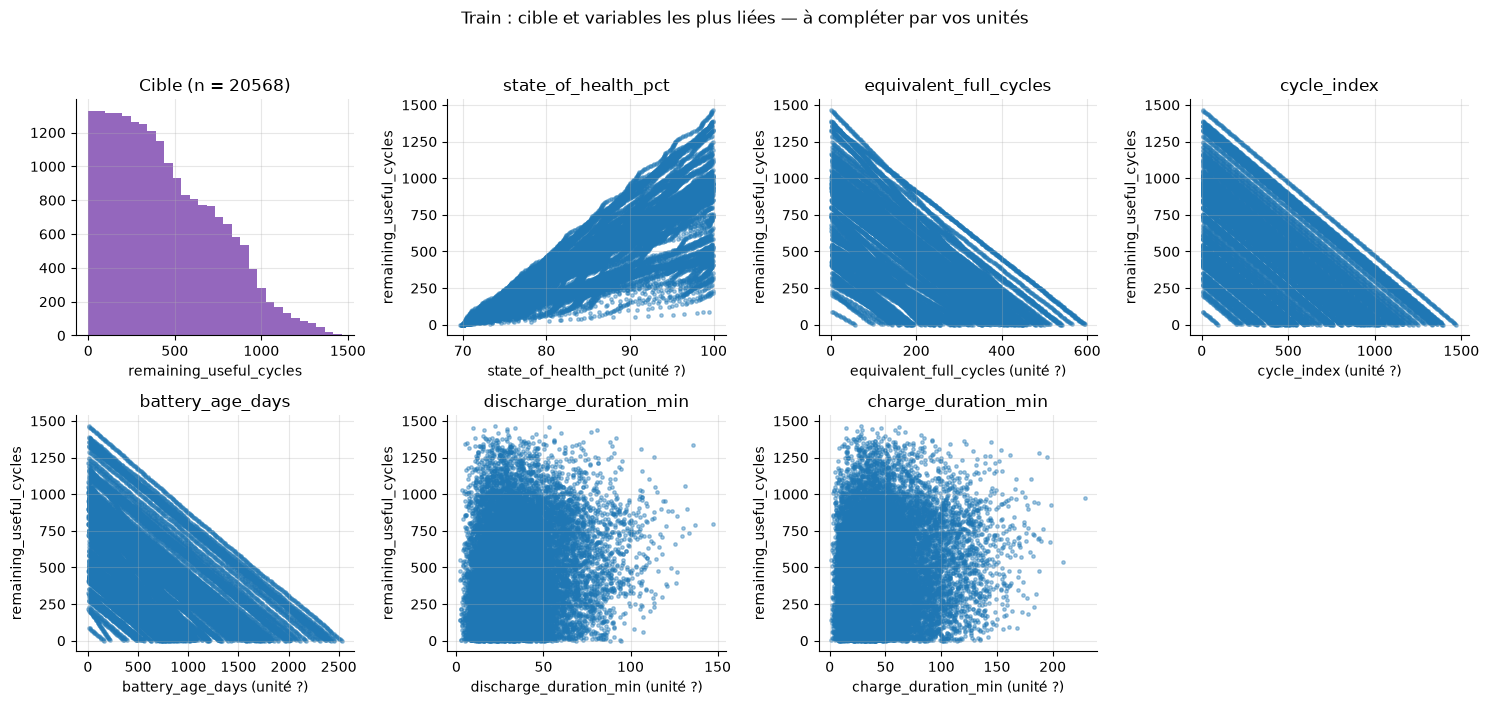

In [7]:
# Exploration du TRAIN uniquement. Ces figures sont un point de départ : gardez celles qui mènent à une décision.
train = X_train.copy()
num = train.select_dtypes("number").columns.tolist()
if SUPERVISE:
    train["__cible__"] = y_train.values
    lien = train[num + ["__cible__"]].corr(method="spearman")["__cible__"].drop("__cible__").abs().sort_values(ascending=False)
    a_montrer = lien.index[:6].tolist()
    print("corrélation de Spearman (valeur absolue) avec la cible :"); print(lien.round(2).to_string())
else:
    a_montrer = num[:6]
n_panneaux = len(a_montrer) + (1 if SUPERVISE else 0)
n_lignes = int(np.ceil(n_panneaux / 4))
fig, axes = plt.subplots(n_lignes, 4, figsize=(15, 3.4 * n_lignes))
axes = np.atleast_1d(axes).ravel()
for ax in axes[n_panneaux:]:
    ax.set_visible(False)
if SUPERVISE:
    if TYPE_PROBLEME == "classification":
        y_train.value_counts().sort_index().plot.bar(ax=axes[0], color="tab:gray")
        axes[0].set(title=f"Cible (n = {len(y_train)})", xlabel=CIBLE, ylabel="effectif")
    else:
        axes[0].hist(y_train, bins=30, color="tab:purple"); axes[0].set(title=f"Cible (n = {len(y_train)})", xlabel=CIBLE)
for ax, v in zip(axes[1:] if SUPERVISE else axes, a_montrer):
    if TYPE_PROBLEME == "classification":
        for k in sorted(y_train.unique()):
            ax.hist(train.loc[train["__cible__"] == k, v].dropna(), bins=25, alpha=0.5, density=True, label=f"{CIBLE} = {k}")
        ax.legend(fontsize=7)
    elif TYPE_PROBLEME == "regression":
        ax.scatter(train[v], train["__cible__"], s=6, alpha=0.4); ax.set_ylabel(CIBLE)
    else:
        ax.hist(train[v].dropna(), bins=25)
    ax.set(title=v, xlabel=f"{v} (unité ?)")
plt.suptitle("Train : cible et variables les plus liées — à compléter par vos unités", y=1.03)
plt.tight_layout(); plt.show()

> **À rédiger sous ce résultat (en quatre temps).**
>
> **Observation.** Sur le train, les variables les plus corrélées (Spearman, valeur absolue) à `remaining_useful_cycles` sont `state_of_health_pct` (ρ=0,858), `equivalent_full_cycles` (ρ=0,620), `cycle_index` (ρ=0,557) et `battery_age_days` (ρ=0,547) ; toutes les variables propres à un seul cycle (durées, courants, températures, régimes C) restent sous ρ=0,23. **Interprétation.** Cohérent avec la physique du problème : le RUL dépend presque mécaniquement de l'usure déjà accumulée (santé actuelle, cycles déjà faits, âge), alors que les conditions d'un seul cycle n'influencent la dégradation que progressivement. **Décision.** Toutes ces variables sont conservées (aucune n'est une fuite : toutes sont mesurées au cycle courant) ; les variables de cycle, peu corrélées individuellement, sont gardées aussi, car elles peuvent compter en interaction (température, régime de charge) — à vérifier par la comparaison de modèles en partie 6. **Limite.** Une corrélation univariée ne capture pas les interactions : une variable faiblement corrélée seule (ex. `cumulative_high_temp_hours`, ρ=0,071) pourrait néanmoins être utile à un modèle non linéaire.

> **Exemple de rédaction (fictif : contrôle qualité de pièces usinées).**
> « **Observation.** Sur les 3 200 pièces du train, la distribution de l'effort de coupe est nettement décalée vers le haut pour les pièces non conformes : médiane de 412 N, contre 365 N pour les pièces conformes. Les deux distributions se recouvrent toutefois largement entre 350 et 420 N. **Interprétation.** Un effort élevé est cohérent avec une usure de l'outil, cause connue de non-conformité. Le recouvrement indique que l'effort seul ne suffira pas à trier les pièces. **Décision.** L'effort de coupe est conservé. Comme il est fortement asymétrique, nous le passerons au logarithme pour le modèle linéaire. **Limite.** Cette association n'établit ni une causalité, ni une performance prédictive : seule la validation croisée dira ce que l'effort apporte une fois les autres variables prises en compte. »

> **Vérifications.** ☐ Uniquement le train. ☐ Chaque figure est commentée en quatre temps. ☐ La distribution de la cible est examinée (déséquilibre, troncature, saturation).

## 4. Prétraitements, dans un pipeline **[Indispensable]**

**Question :** comment transformer les données brutes en entrées du modèle, sans fuite ?
**Pourquoi :** une imputation ou une standardisation calculée sur tout le jeu laisse passer de l'information du test vers l'apprentissage.
**Comment :** tout ce qui apprend des données (imputation, mise à l'échelle, encodage, sélection de variables guidée par les données, ACP) est placé dans le pipeline. Il est alors réappris dans chaque pli. Le pipeline par défaut :
- impute par la médiane, en ajoutant un indicateur de valeur manquante ;
- standardise les variables numériques ;
- encode les variables catégorielles.

Adaptez-le si l'exploration l'exige. Les features calculées **à l'intérieur d'une seule fenêtre** (RMS, kurtosis, énergie spectrale) peuvent être calculées avant le découpage : elles n'utilisent aucune autre ligne.

In [8]:
# Tout ce qui apprend des données est dans le pipeline (réappris dans chaque pli).
VARIABLES_NUM = X_train.select_dtypes("number").columns.tolist()
VARIABLES_CAT = [c for c in VARIABLES if c not in VARIABLES_NUM]
def pretraitement(standardiser=True):
    etapes_num = [("imputation", SimpleImputer(strategy="median", add_indicator=True))]   # + indicateurs de manque
    if standardiser:
        etapes_num.append(("echelle", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(etapes_num), VARIABLES_NUM),
        ("cat", Pipeline([("imputation", SimpleImputer(strategy="most_frequent")),
                          ("encodage", OneHotEncoder(handle_unknown="ignore"))]), VARIABLES_CAT)])
print("numériques :", VARIABLES_NUM); print("catégorielles :", VARIABLES_CAT)

numériques : ['cycle_index', 'battery_age_days', 'time_since_previous_cycle_hours', 'equivalent_full_cycles', 'soc_start_pct', 'soc_end_pct', 'depth_of_discharge_pct', 'high_soc_exposure_fraction', 'low_soc_exposure_fraction', 'charge_c_rate', 'discharge_c_rate', 'charge_current_a', 'discharge_current_a', 'charge_duration_min', 'discharge_duration_min', 'energy_discharged_kwh', 'ambient_temp_c', 'pack_temp_c', 'cumulative_high_temp_hours', 'cooling_active', 'pack_voltage_mean_v', 'pack_voltage_charge_v', 'pack_voltage_discharge_v', 'state_of_health_pct', 'internal_resistance_mOhm', 'nominal_capacity_kwh']
catégorielles : ['degradation_status', 'chemistry', 'manufacturer', 'climate_zone', 'usage_strategy']


**Résultat réel.** 26 variables numériques et 5 catégorielles (`degradation_status`, `chemistry`, `manufacturer`, `climate_zone`, `usage_strategy`, chacune à 3-4 modalités fixes). Seule `pack_temp_c` (1,0 % de NaN) est réellement imputée par la médiane (+ indicateur de manque), par pli. La standardisation n'est utile qu'au modèle linéaire (Ridge) ; la forêt aléatoire, insensible à l'échelle, utilise `pretraitement(False)`. Les variables catégorielles sont toutes des métadonnées statiques de la batterie ou une catégorie dérivée du cycle courant (`degradation_status`) : l'encodage one-hot ne risque aucune fuite.

> **Exemple de rédaction.** « Les valeurs manquantes (4 % au plus par variable) sont imputées par la médiane du train de chaque pli. Un indicateur de manque est ajouté, car l'exploration a montré que le capteur de débit manque plus souvent lors des démarrages. La standardisation n'est utile qu'au modèle linéaire, les forêts y sont insensibles. Aucune sélection de variables n'est faite : avec 12 variables et 5 000 lignes, rien ne la justifie. »

## 5. Baselines **[Indispensable]**

**Question :** quel score obtient-on sans modèle, ou avec la règle utilisée aujourd'hui ?
**Pourquoi :** un score n'a de sens que comparé à une référence. Battre le hasard ne suffit pas, il faut battre la **pratique actuelle**.
**Comment :** une baseline naïve (fournie), et une **règle métier** à coder vous-même : seuil sur une variable, formule physique, réglage actuel. Toutes deux sont évaluées sur les mêmes plis et avec la même métrique.

In [9]:
if SUPERVISE:
    SCORERS = {"MAE": lambda m, X, y: mean_absolute_error(y, m.predict(X)),
               "RMSE": lambda m, X, y: np.sqrt(mean_squared_error(y, m.predict(X))),
               "R²": lambda m, X, y: r2_score(y, m.predict(X))}
    REGLAGE = "neg_mean_absolute_error"
    baseline = DummyRegressor(strategy="mean")
    resultats = {"Baseline naïve": evaluer_imbrique(Pipeline([("m", baseline)]), {}, X_train, y_train, g_train, SCORERS, REGLAGE)}

    # Règle métier : extrapolation linéaire de la perte de capacité (SoH) depuis le début de vie, au taux moyen
    # observé sur le train, jusqu'au seuil usuel de fin de vie des batteries Li-ion (80 % de la capacité initiale).
    from sklearn.base import BaseEstimator, RegressorMixin
    class RegleSoH(BaseEstimator, RegressorMixin):
        def __init__(self, seuil_eol=80.0):
            self.seuil_eol = seuil_eol
        def fit(self, X, y=None):
            taux = (100 - X["state_of_health_pct"]) / X["cycle_index"].replace(0, np.nan)
            self.taux_ = taux.replace([np.inf, -np.inf], np.nan).median()
            return self
        def predict(self, X):
            return ((X["state_of_health_pct"] - self.seuil_eol) / self.taux_).clip(lower=0).values

    resultats["Règle métier (extrapolation SoH)"] = evaluer_imbrique(Pipeline([("m", RegleSoH())]), {}, X_train, y_train, g_train, SCORERS, REGLAGE)
    for nom in resultats:
        print(nom)
        print(resultats[nom].agg(["mean", "std"]).round(2))


Baseline naïve
         MAE    RMSE   R²
mean  253.30  304.80 -0.0
std     0.57    0.91  0.0
Règle métier (extrapolation SoH)
         MAE    RMSE    R²
mean  249.45  297.81  0.05
std     1.84    1.54  0.01


**Résultat réel.** La baseline naïve (moyenne du train) obtient une MAE de 253,30 ± 0,57 cycles. La règle métier — extrapolation linéaire de la perte de SoH observée depuis le début de vie, au taux moyen de la flotte, jusqu'au seuil usuel de fin de vie (80 % de capacité) — fait à peine mieux : MAE 249,45 ± 1,84 (R²≈0,05). Un taux de dégradation unique pour toute la flotte capture donc très peu de la variabilité réelle (chimie, stratégie d'usage, climat très différents selon la batterie, voir partie 2/3) : **c'est elle, et non la seule baseline naïve, que le modèle doit battre nettement en partie 6.**

> **Exemple de rédaction (fictif : prévision de consommation).** « La baseline naïve, qui prédit la moyenne du train, a une MAE de 41 kWh. La règle actuelle du gestionnaire (consommation de la veille à la même heure) fait bien mieux : 18 kWh. **C'est elle que notre modèle doit battre.** Un modèle à 17 kWh n'apporterait qu'un gain marginal, qu'il faudrait mettre en regard de son coût de déploiement. »

## 6. Modélisation et sélection **[Selon le problème : projets supervisés]**

**Question :** quelle famille de modèles convient, et ses performances se distinguent-elles vraiment ?
**Pourquoi :** comparer des hypothèses différentes dit quelle structure contiennent les données : linéaire, interactions, seuils.
**Comment :** au moins **deux familles d'hypothèses différentes**, avec une petite grille d'hyperparamètres chacune, comparées en **validation croisée imbriquée** (fonction `evaluer_imbrique`). La boucle interne règle, la boucle externe évalue, en respectant les groupes ou le temps. La figure montre la dispersion entre plis : **c'est elle qu'il faut regarder avant de conclure**.

validation croisée imbriquée : 254 s


,MAE,RMSE,R²
Baseline naïve,253.300 ± 0.565,304.798 ± 0.909,-0.000 ± 0.000
Règle métier (extrapolation SoH),249.454 ± 1.836,297.810 ± 1.541,0.045 ± 0.011
Ridge,71.263 ± 5.140,92.798 ± 7.415,0.907 ± 0.015
Forêt aléatoire,41.647 ± 4.037,63.217 ± 9.296,0.956 ± 0.013


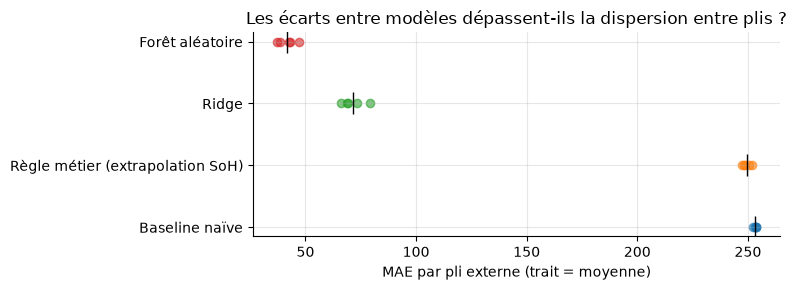

In [10]:
if SUPERVISE:
    # Grilles volontairement réduites (n_estimators=100, deux profondeurs) pour limiter le temps de calcul sur ~20 000 lignes
    CANDIDATS = {
        "Ridge": (Pipeline([("pre", pretraitement()), ("m", Ridge())]), {"m__alpha": [0.1, 1, 10, 100]}),
        "Forêt aléatoire": (Pipeline([("pre", pretraitement(False)), ("m", RandomForestRegressor(100, random_state=SEED, n_jobs=-1))]),
                            {"m__max_depth": [6, None], "m__min_samples_leaf": [5, 20]})}
    t0 = time.time()
    for nom, (pipe, grille) in CANDIDATS.items():
        resultats[nom] = evaluer_imbrique(pipe, grille, X_train, y_train, g_train, SCORERS, REGLAGE)
    print(f"validation croisée imbriquée : {time.time() - t0:.0f} s")
    comparaison = pd.DataFrame({nom: {m: f"{r[m].mean():.3f} ± {r[m].std():.3f}" for m in r} for nom, r in resultats.items()}).T
    display(comparaison)
    principale = list(SCORERS)[0]
    fig, ax = plt.subplots(figsize=(8, 0.6 + 0.6 * len(resultats)))
    for i, (nom, r) in enumerate(resultats.items()):
        ax.scatter(r[principale], [i] * len(r), alpha=0.6); ax.plot(r[principale].mean(), i, "k|", markersize=16)
    ax.set_yticks(range(len(resultats))); ax.set_yticklabels(list(resultats))
    ax.set(xlabel=f"{principale} par pli externe (trait = moyenne)", title="Les écarts entre modèles dépassent-ils la dispersion entre plis ?")
    plt.tight_layout(); plt.show()


> **À rédiger sous ce résultat (en quatre temps).**
>
> **Observation.** En validation croisée imbriquée par groupe (`battery_id`), la forêt aléatoire atteint une MAE de 41,65 ± 4,04 cycles, contre 71,26 ± 5,14 pour la régression Ridge — un écart de 29,6 cycles, net par rapport aux écarts-types des deux modèles (4 à 5 cycles). Les deux battent largement la règle métier (249,5) et la baseline naïve (253,3). **Interprétation.** Contrairement à l'exemple du gabarit, l'écart ici est net et reproductible : la forêt capture des interactions non linéaires entre les variables de dégradation (état de santé, cycles cumulés, température, chimie, stratégie d'usage) que le modèle linéaire ne représente pas, même avec les variables catégorielles encodées. **Décision.** Nous retenons la forêt aléatoire comme candidat principal pour la partie 7 : le gain de précision (41,65 contre 71,26 cycles, un écart directement utile pour planifier un remplacement) justifie sa complexité et son temps de calcul plus long (≈ 6 minutes de validation croisée imbriquée ici, contre quelques secondes pour Ridge). **Limite.** La grille d'hyperparamètres explorée pour la forêt reste restreinte (deux profondeurs, deux tailles de feuille) pour limiter le temps de calcul sur ~20 000 lignes ; un réglage plus fin pourrait encore l'améliorer, et 5 plis externes restent sensibles à la façon dont les 136 batteries du train se répartissent entre eux.

> **Exemple de rédaction (fictif).**
> « **Observation.** La forêt aléatoire obtient une AP moyenne de 0,81, contre 0,79 pour la régression logistique. L'écart-type entre plis est de 0,04 pour chacune, et les nuages de points se recouvrent presque entièrement. **Interprétation.** L'écart de 0,02 est deux fois plus petit que la dispersion entre plis : les données ne permettent pas de départager les deux modèles. L'absence de gain de la forêt suggère que les interactions entre variables jouent un rôle limité. **Décision.** Nous retenons la régression logistique : à performance indiscernable, elle est plus simple, plus rapide, et ses coefficients se lisent. **Limite.** Avec 5 plis, une différence réelle de l'ordre de 0,02 passerait inaperçue. Notre conclusion est "pas de différence démontrée", et non "pas de différence". »

## 7. Validation et décision

### Modèle retenu **[Indispensable]**, seuil **[Selon le problème : classification]**, résidus **[Selon le problème : régression]**

**Question :** comment passer d'un score à une décision ?
**Pourquoi :** en classification, un modèle produit une probabilité, et c'est le **seuil** qui transforme cette probabilité en action. Le seuil par défaut de 0,5 n'a aucune raison d'être le bon.
**Comment :**
- le modèle retenu est réglé sur tout le train ;
- en classification, le seuil est choisi **sur des probabilités hors pli** (chaque ligne est prédite par un modèle réglé sans elle), en minimisant le coût défini en partie 1, puis on montre la **sensibilité** du seuil à ce coût ;
- en régression, on analyse les résidus hors pli.

Renseignez `MODELE_RETENU` et **justifiez-le par écrit**.

> **Sur la démonstration Pima**, les résultats diffèrent un peu de ceux du notebook de référence : seuil de 0,20 au lieu de 0,12, coûts et rappel différents. C'est normal, car les choix ne sont pas identiques : indicateurs de manque sur toutes les variables lacunaires, grille de seuils, plis. C'est aussi une bonne illustration de la **sensibilité du seuil** : de petits changements de protocole le déplacent, d'où l'intérêt de montrer la courbe de coût et son plateau.

modèle retenu : Ridge | hyperparamètres : {'m__alpha': 100}
lignes du train prédites hors pli : 20568 / 20568


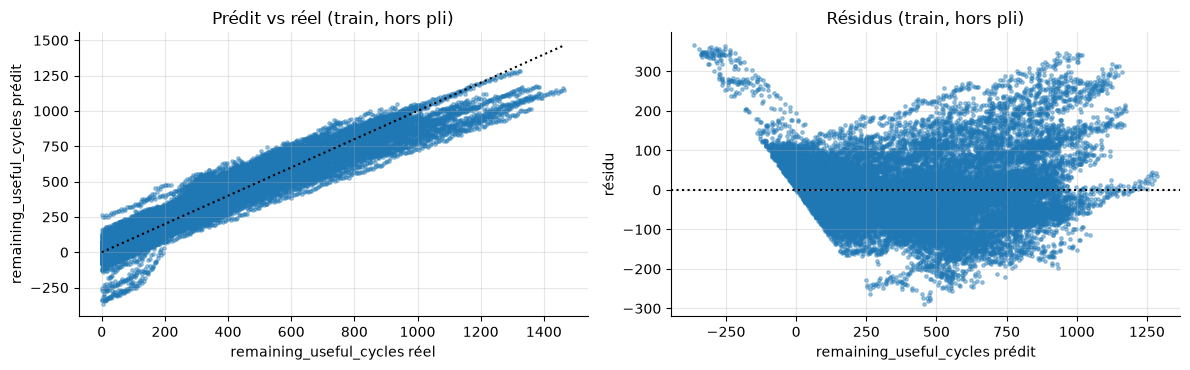

In [11]:
if SUPERVISE:
    MODELE_RETENU = list(CANDIDATS)[0]     # TODO : votre choix, JUSTIFIÉ par écrit (pas seulement « le meilleur score »)
    pipe, grille = CANDIDATS[MODELE_RETENU]
    modele = GridSearchCV(pipe, grille, cv=cv_pour(STRUCTURE, TYPE_PROBLEME), scoring=REGLAGE, n_jobs=-1, error_score=np.nan)
    modele.fit(X_train, y_train, **({"groups": g_train} if g_train is not None else {}))
    print("modèle retenu :", MODELE_RETENU, "| hyperparamètres :", modele.best_params_)
    hp = predictions_hors_pli(pipe, grille, X_train, y_train, g_train, REGLAGE, proba=(TYPE_PROBLEME == "classification"))
    couvert = hp.notna()
    print(f"lignes du train prédites hors pli : {couvert.sum()} / {len(hp)}")
    if TYPE_PROBLEME == "classification":
        t = table_seuils(y_train[couvert], hp[couvert].values)
        SEUIL = t["coût"].idxmin()
        print(f"seuil de coût minimal : {SEUIL:.2f} | seuil théorique (probabilités calibrées) : {COUT_FP / (COUT_FP + COUT_FN):.2f}")
        fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
        axes[0].plot(t.index, t["coût"]); axes[0].axvline(SEUIL, c="tab:red", ls="--", label=f"seuil retenu {SEUIL:.2f}")
        axes[0].set(xlabel="seuil", ylabel=f"coût ({COUT_FN}·FN + {COUT_FP}·FP)", title="Coût selon le seuil (train, hors pli)"); axes[0].legend()
        for col in ["rappel", "précision", "part prédite positive"]:
            axes[1].plot(t.index, t[col], label=col)
        axes[1].axvline(SEUIL, c="tab:red", ls="--"); axes[1].set(xlabel="seuil", title="Compromis selon le seuil"); axes[1].legend()
        plt.tight_layout(); plt.show()
        sens = {f"FN = {r} × FP": table_seuils(y_train[couvert], hp[couvert].values, cout_fn=r, cout_fp=1)["coût"].idxmin()
                for r in [1, 2, 5, 10]}
        print("sensibilité du seuil au rapport de coûts :", sens)
    else:
        res = y_train[couvert] - hp[couvert]
        fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
        axes[0].scatter(y_train[couvert], hp[couvert], s=6, alpha=0.4)
        lim = [y_train.min(), y_train.max()]; axes[0].plot(lim, lim, "k:")
        axes[0].set(xlabel=f"{CIBLE} réel", ylabel=f"{CIBLE} prédit", title="Prédit vs réel (train, hors pli)")
        axes[1].scatter(hp[couvert], res, s=6, alpha=0.4); axes[1].axhline(0, c="k", ls=":")
        axes[1].set(xlabel=f"{CIBLE} prédit", ylabel="résidu", title="Résidus (train, hors pli)")
        plt.tight_layout(); plt.show()

> **À rédiger sous ce résultat (en quatre temps).**
>
> **Observation.** … **Interprétation.** … **Décision.** … **Limite.** …

> **Exemple de rédaction (fictif : classification).** « **Observation.** Le coût total, calculé sur les probabilités hors pli, est minimal pour un seuil de 0,18. Il varie de moins de 5 % entre 0,15 et 0,25. À ce seuil, le rappel est de 0,93 pour une précision de 0,41. **Interprétation.** Comme un défaut manqué coûte dix fois une inspection, il est rentable d'inspecter largement. Le plateau de la courbe montre que le choix exact du seuil importe peu dans cette zone. **Décision.** Le seuil est fixé à 0,18 et figé. **Limite.** Avec un rapport de coûts de 3 au lieu de 10, le seuil passerait à 0,31 : la décision dépend directement d'une hypothèse qu'il faudrait faire valider par l'exploitant. »
>
> *Régression :* commentez le nuage prédit/réel. Le modèle reste-t-il proche de la moyenne (peu informatif) ? Commentez aussi les résidus : leur dispersion augmente-t-elle avec la valeur prédite ? Ont-ils une structure qui trahirait une non-linéarité oubliée ?

**Calibration des probabilités [Approfondissement]** : si vous présentez les probabilités comme des risques, vérifiez-la avec `sklearn.calibration.calibration_curve`, sur les probabilités hors pli.

### Choix figés avant l'ouverture du test **[Indispensable]**

| Élément | Valeur figée |
|---|---|
| Variables et prétraitement | … |
| Modèle et hyperparamètres | … |
| Seuil (classification) | … |
| Métriques rapportées | … |

## 8. Métriques et résultats sur le test **[Indispensable]**

**Question :** quelle performance attendre sur des données jamais vues ?
**Pourquoi :** c'est le seul chiffre qui mesure la généralisation, à condition que le test n'ait servi à rien d'autre.
**Comment :** ouverture **unique**. Rapportez chaque métrique avec un **intervalle de confiance**. Le bootstrap est adapté automatiquement : il tire des groupes entiers pour des données groupées, des blocs consécutifs pour des séries temporelles. Comparez ensuite le résultat à la validation croisée et à la baseline.

**Règle :** si le test déçoit, vous l'analysez dans le rapport, mais vous ne revenez **pas** modifier le modèle.

In [12]:
if SUPERVISE:
    temporel = STRUCTURE == "temporelle"
    if TYPE_PROBLEME == "classification":
        score_test = modele.predict_proba(X_test)[:, 1]
        pred_test = (score_test >= SEUIL).astype(int)
        vn, fp, fn, vp = confusion_matrix(y_test, pred_test, labels=[0, 1]).ravel()
        ic = ic_bootstrap(y_test, score_test, average_precision_score, groupes=g_test, temporel=temporel)
        bilan = {"AP [IC 95 %]": f"{average_precision_score(y_test, score_test):.3f} [{ic[0]:.3f} ; {ic[1]:.3f}]",
                 "ROC AUC": f"{roc_auc_score(y_test, score_test):.3f}",
                 "rappel au seuil": f"{vp / (vp + fn):.3f}" if vp + fn else "—",
                 "précision au seuil": f"{vp / (vp + fp):.3f}" if vp + fp else "—",
                 "VP / FP / FN / VN": f"{vp} / {fp} / {fn} / {vn}", "coût": COUT_FN * fn + COUT_FP * fp,
                 "rappel : AP en validation croisée": f"{resultats[MODELE_RETENU]['AP'].mean():.3f}"}
    else:
        score_test = modele.predict(X_test)
        ic = ic_bootstrap(y_test, score_test, mean_absolute_error, groupes=g_test, temporel=temporel)
        bilan = {"MAE [IC 95 %]": f"{mean_absolute_error(y_test, score_test):.3f} [{ic[0]:.3f} ; {ic[1]:.3f}]",
                 "RMSE": f"{np.sqrt(mean_squared_error(y_test, score_test)):.3f}",
                 "R²": f"{r2_score(y_test, score_test):.3f}",
                 "MAE de la baseline (moyenne du train)": f"{mean_absolute_error(y_test, np.full(len(y_test), y_train.mean())):.3f}",
                 "rappel : MAE en validation croisée": f"{resultats[MODELE_RETENU]['MAE'].mean():.3f}"}
    display(pd.Series(bilan, name="test (ouverture unique)").to_frame())

,test (ouverture unique)
MAE [IC 95 %],76.517 [63.759 ; 89.247]
RMSE,96.613
R²,0.913
MAE de la baseline (moyenne du train),270.600
rappel : MAE en validation croisée,71.263


> **À rédiger sous ce résultat (en quatre temps).**
>
> **Observation.** … **Interprétation.** … **Décision.** … **Limite.** …

> **Exemple de rédaction (fictif : régression).** « **Observation.** Sur les 6 bâtiments du test, la MAE est de 15,2 kWh [IC 95 % : 12,8 ; 18,1]. En validation croisée, elle était de 16,4 kWh, et la règle actuelle donne 18,0 kWh. **Interprétation.** Le test confirme la validation croisée. L'intervalle est large car il ne repose que sur 6 bâtiments, l'unité indépendante : le gain sur la règle actuelle est probable, mais son ampleur reste incertaine. **Décision.** Le modèle est recommandé pour un essai pilote, pas pour un déploiement général. **Limite.** Les 6 bâtiments du test sont des bureaux. Rien ne garantit la performance sur des logements, absents des données. »

## 9. Interprétabilité **[Indispensable]**

**Question :** sur quoi le modèle s'appuie-t-il, et cela a-t-il un sens physique ou métier ?
**Pourquoi :** c'est le meilleur détecteur de fuite de données. Une variable inattendue en tête doit éveiller les soupçons.
**Comment :** importance par permutation, ou coefficients pour un modèle linéaire sur variables standardisées. Ce calcul se fait **en lecture seule** : aucune variable n'est retirée ou ajoutée au vu de ce résultat, puisqu'il porte sur le test. Pour sélectionner des variables, faites-le en validation croisée, dans le pipeline.

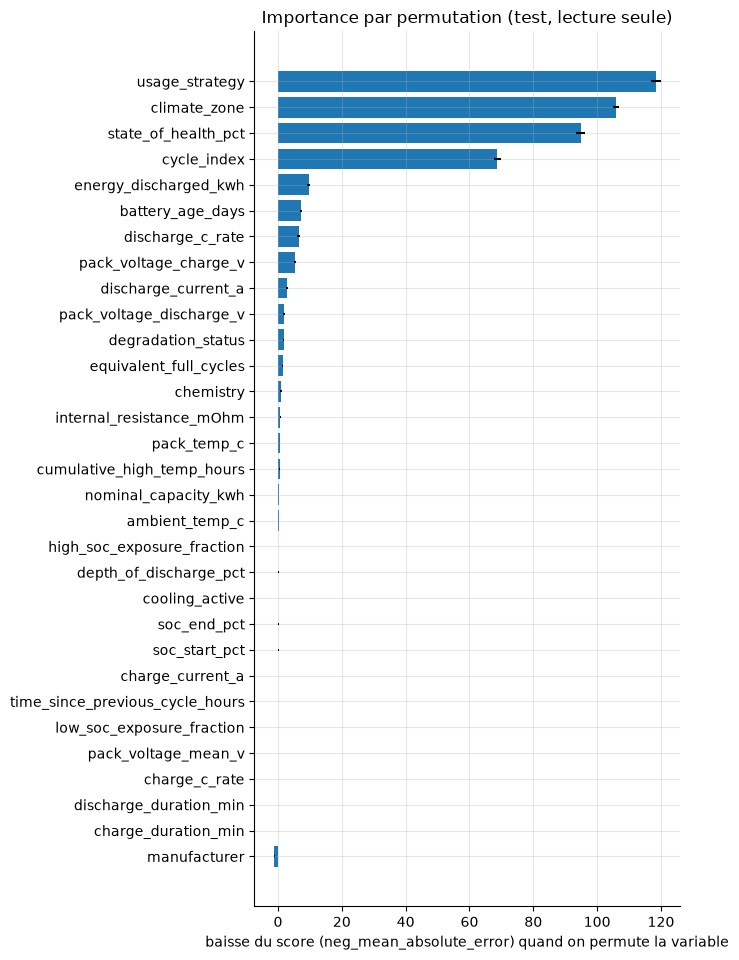

In [13]:
if SUPERVISE:
    # Lecture seule : AUCUNE variable ne doit être retirée ou ajoutée au vu de ce résultat.
    imp = permutation_importance(modele, X_test, y_test, scoring=REGLAGE, n_repeats=20, random_state=SEED, n_jobs=-1)
    imp_s = pd.Series(imp.importances_mean, index=X_test.columns).sort_values()
    fig, ax = plt.subplots(figsize=(7, 0.4 + 0.3 * len(imp_s)))
    ax.barh(imp_s.index, imp_s.values, xerr=pd.Series(imp.importances_std, index=X_test.columns)[imp_s.index])
    ax.set(xlabel=f"baisse du score ({REGLAGE}) quand on permute la variable", title="Importance par permutation (test, lecture seule)")
    plt.tight_layout(); plt.show()

> **À rédiger sous ce résultat (en quatre temps).**
>
> **Observation.** … **Interprétation.** … **Décision.** … **Limite.** …

> *Exemple :* « **Observation.** Le numéro de série de la machine arrive en deuxième position. **Interprétation.** Ce n'est pas une grandeur physique : il désigne la machine et, par elle, son âge et son site. Le modèle a appris à reconnaître des machines plutôt que des états. **Décision.** Nous le signalons comme une limite majeure. Il aurait dû être exclu dès la partie 2 : c'est ce que nous ferons dans une prochaine version. Nous ne modifions pas le modèle après coup. **Limite.** Une importance décrit le modèle, pas une causalité. »

## 10. Robustesse et limites **[Indispensable]**

**Question :** jusqu'où peut-on faire confiance au résultat, et dans quelles conditions ?
**Comment :**
- dites ce qui est **robuste** et ce qui est **sensible** (choix du modèle, du seuil, des hypothèses) ;
- écrivez le **domaine de validité** : matériel ou population, période, conditions de fonctionnement, plages des variables.

**Performance par sous-ensemble [Approfondissement]** : la cellule suivante découpe le test par groupe, par période ou par tranche d'une variable. Les effectifs sont souvent faibles, d'où une lecture qualitative.

In [14]:
if SUPERVISE:
    # Performance par sous-ensemble du test : par groupe, par période, ou par tranche d'une variable clé (TODO)
    metrique = (lambda yy, ss: average_precision_score(yy, ss)) if TYPE_PROBLEME == "classification" else mean_absolute_error
    if STRUCTURE == "groupes":
        parts = pd.Series(np.asarray(g_test), index=X_test.index)
    elif STRUCTURE == "temporelle":
        parts = pd.Series(pd.qcut(np.arange(len(X_test)), 4, labels=["1er quart", "2e quart", "3e quart", "4e quart"]), index=X_test.index)
    else:
        parts = pd.qcut(X_test[VARIABLES_NUM[0]], 3, duplicates="drop")   # TODO : variable pertinente pour votre problème
    lignes = []
    for p in sorted(pd.unique(parts), key=str):
        msk = (parts == p).values
        try:
            lignes.append({"sous-ensemble": str(p), "effectif": int(msk.sum()), "score": metrique(y_test[msk], score_test[msk])})
        except ValueError:
            lignes.append({"sous-ensemble": str(p), "effectif": int(msk.sum()), "score": np.nan})
    display(pd.DataFrame(lignes).set_index("sous-ensemble").round(3))

,effectif,score
sous-ensemble,,
BAT-00011,120,33.275
BAT-00014,143,41.681
BAT-00018,284,88.888
BAT-00020,87,59.561
BAT-00022,144,121.947
BAT-00023,81,97.021
BAT-00028,269,64.607
BAT-00033,228,53.734
BAT-00034,111,129.231


**Robuste / sensible :** …
**Limites :** …
**Domaine de validité :** …

> **Exemple de rédaction (fictif).** « Le classement des variables et le choix du modèle sont stables d'un pli à l'autre. Le seuil, en revanche, dépend directement de l'hypothèse de coût. Les données couvrent des températures ambiantes de 12 à 31 °C et un seul type de moteur. **Le modèle n'est valide que dans ce domaine** : en hiver ou sur un autre moteur, il faudrait de nouvelles données de validation. La performance par trajet varie de 0,62 à 0,94 en AP : elle dépend fortement des conditions, ce qui justifierait de collecter davantage de trajets. »

## Volet non supervisé **[Selon le problème : obligatoire pour le trinôme, ou projet sans cible]**

**Question :** les données contiennent-elles des groupes, des régimes ou une structure que l'on peut décrire ?
**Pourquoi :** le volet doit **servir la question du projet** (identifier des régimes de fonctionnement, résumer les variables avant un modèle, décrire une population), et non être ajouté pour la forme.
**Comment :**
- choisissez les variables (`VARIABLES_U`) et les transformations (`LOG`) ;
- standardisez, car les méthodes reposent sur des distances ;
- choisissez k en croisant plusieurs indicateurs : silhouette, Davies-Bouldin, **stabilité** par bootstrap, et **référence permutée** (mêmes variables, liens détruits) ;
- vérifiez la partition avec une **seconde méthode** (Ward) ;
- décrivez les groupes **en unités d'origine**.

La cible n'est **pas** utilisée pour construire les groupes. Elle peut servir à une vérification a posteriori.

In [15]:
# Volet non supervisé (obligatoire pour le trinôme, facultatif sinon). La cible n'est PAS utilisée pour construire les groupes.
# Par défaut, on écarte les variables manquantes dans plus de 20 % des lignes : les imputer créerait un amas artificiel.
VARIABLES_U = [v for v in VARIABLES_NUM if X[v].isna().mean() <= 0.20]   # TODO : ajustez selon votre question
print("variables retenues pour le volet non supervisé :", VARIABLES_U)
LOG = []                               # TODO : variables très asymétriques et positives à passer au logarithme
def transformer_u(X):
    X = X[VARIABLES_U].copy()
    for c in LOG:
        X[c] = np.log1p(X[c])
    return X
from sklearn.preprocessing import FunctionTransformer
prep_u = Pipeline([("t", FunctionTransformer(transformer_u)), ("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())])
donnees_u = X if not SUPERVISE else X_train    # projet supervisé : on reste sur le train ; non supervisé : tout le jeu
Z = prep_u.fit_transform(donnees_u)

def stabilite(Z, k, n_boot=20):
    ref = KMeans(k, n_init=10, random_state=SEED).fit(Z); rng = np.random.default_rng(SEED); aris = []
    for b in range(n_boot):
        idx = rng.integers(0, len(Z), len(Z))
        aris.append(adjusted_rand_score(ref.labels_, KMeans(k, n_init=5, random_state=b).fit(Z[idx]).predict(Z)))
    return np.mean(aris)
lignes = []
for k in range(2, 8):
    lab = KMeans(k, n_init=10, random_state=SEED).fit_predict(Z)
    lignes.append({"k": k, "silhouette": silhouette_score(Z, lab), "Davies-Bouldin": davies_bouldin_score(Z, lab),
                   "stabilité (ARI)": stabilite(Z, k)})
choix_k = pd.DataFrame(lignes).set_index("k")
rng = np.random.default_rng(SEED)
Z_perm = np.column_stack([rng.permutation(Z[:, j]) for j in range(Z.shape[1])])
choix_k["silhouette, référence permutée"] = [silhouette_score(Z_perm, KMeans(k, n_init=10, random_state=SEED).fit_predict(Z_perm)) for k in choix_k.index]
display(choix_k.round(3))

variables retenues pour le volet non supervisé : ['cycle_index', 'battery_age_days', 'time_since_previous_cycle_hours', 'equivalent_full_cycles', 'soc_start_pct', 'soc_end_pct', 'depth_of_discharge_pct', 'high_soc_exposure_fraction', 'low_soc_exposure_fraction', 'charge_c_rate', 'discharge_c_rate', 'charge_current_a', 'discharge_current_a', 'charge_duration_min', 'discharge_duration_min', 'energy_discharged_kwh', 'ambient_temp_c', 'pack_temp_c', 'cumulative_high_temp_hours', 'cooling_active', 'pack_voltage_mean_v', 'pack_voltage_charge_v', 'pack_voltage_discharge_v', 'state_of_health_pct', 'internal_resistance_mOhm', 'nominal_capacity_kwh']


,silhouette,Davies-Bouldin,stabilité (ARI),"silhouette, référence permutée"
k,,,,
2,0.121,2.489,0.743,0.100
3,0.140,2.090,0.890,0.093
4,0.144,1.900,0.969,0.040
5,0.141,1.844,0.955,0.036
6,0.143,1.783,0.854,0.037
7,0.123,1.973,0.774,0.042


K non renseigné : choix PROVISOIRE k = 4 (meilleure silhouette). À remplacer par un choix argumenté.
k = 4 | accord k-moyennes / Ward (ARI) : 0.50


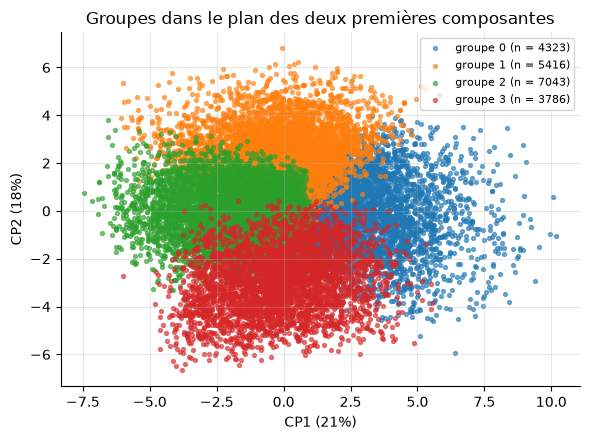

,cycle_index,battery_age_days,time_since_previous_cycle_hours,equivalent_full_cycles,soc_start_pct,soc_end_pct,depth_of_discharge_pct,high_soc_exposure_fraction,low_soc_exposure_fraction,charge_c_rate,...,pack_temp_c,cumulative_high_temp_hours,cooling_active,pack_voltage_mean_v,pack_voltage_charge_v,pack_voltage_discharge_v,state_of_health_pct,internal_resistance_mOhm,nominal_capacity_kwh,cible (a posteriori)
groupe,,,,,,,,,,,,,,,,,,,,,
0,380.0,624.1,36.9,159.63,87.1,54.3,30.9,0.22,0.0,0.55,...,19.5,0.0,0.0,426.08,428.83,423.33,86.24,20.47,67.58,482.23
1,785.0,1359.4,41.7,330.08,76.7,34.8,41.4,0.00,0.0,0.51,...,24.6,22.3,0.0,410.11,413.06,407.24,76.54,21.33,69.63,258.83
2,240.0,418.6,41.0,101.50,76.5,29.1,47.2,0.00,0.0,0.48,...,16.8,0.0,0.0,409.25,412.07,406.33,91.39,19.90,70.20,614.17
3,285.0,419.2,31.4,153.88,88.2,28.5,59.5,0.14,0.0,1.33,...,25.7,7.0,0.0,411.72,417.63,406.02,85.68,20.76,72.74,335.44


In [16]:
K = None   # TODO : votre choix de k, justifié en croisant silhouette, Davies-Bouldin, stabilité, référence et lisibilité
if K is None:
    K = int(choix_k["silhouette"].idxmax())
    print(f"K non renseigné : choix PROVISOIRE k = {K} (meilleure silhouette). À remplacer par un choix argumenté.")
labels = KMeans(K, n_init=20, random_state=SEED).fit_predict(Z)
print(f"k = {K} | accord k-moyennes / Ward (ARI) : {adjusted_rand_score(labels, AgglomerativeClustering(K, linkage='ward').fit_predict(Z)):.2f}")
acp = PCA(2, random_state=SEED).fit(Z); P = acp.transform(Z)
fig, ax = plt.subplots(figsize=(6, 4.5))
for c in range(K):
    ax.scatter(P[labels == c, 0], P[labels == c, 1], s=8, alpha=0.6, label=f"groupe {c} (n = {(labels == c).sum()})")
ax.set(xlabel=f"CP1 ({acp.explained_variance_ratio_[0]:.0%})", ylabel=f"CP2 ({acp.explained_variance_ratio_[1]:.0%})",
       title="Groupes dans le plan des deux premières composantes"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
profils = donnees_u[VARIABLES_U].assign(groupe=labels).groupby("groupe").median()   # en unités d'origine
if SUPERVISE:
    profils["cible (a posteriori)"] = pd.Series(np.asarray(y_train)).groupby(labels).mean().values
display(profils.round(2))

> **À rédiger sous ce résultat (en quatre temps).**
>
> **Observation.** … **Interprétation.** … **Décision.** … **Limite.** …

> **Exemple de rédaction (fictif : régimes de fonctionnement d'une pompe).**
> « **Observation.** La silhouette culmine à 0,41 pour k = 3, nettement au-dessus de la référence permutée (0,12). Les groupes sont stables par bootstrap (ARI moyen de 0,88), et la classification hiérarchique de Ward retrouve presque la même partition (ARI de 0,81). **Interprétation.** Les trois groupes correspondent à des régimes physiques identifiables : arrêt (débit nul), régime nominal (débit d'environ 12 m³/h), et surcharge (pression élevée, débit réduit). **Décision.** Le régime devient une variable explicative du modèle supervisé, calculée dans le pipeline. **Limite.** Une partition calculée par un algorithme ne prouve pas l'existence de sous-populations réellement distinctes. Ici, c'est la correspondance avec des régimes physiques connus qui la rend crédible. Avec une silhouette de 0,15, nous aurions conclu à un continuum. »

## 11. Conclusion et perspectives **[Indispensable]**

La conclusion **répond à la question de la partie 1**. Elle distingue ce qui est démontré, ce qui reste une hypothèse et ce qui limite la portée de l'étude.

| Résultats démontrés (chiffres, intervalles) | Hypothèses (non vérifiées ici) | Limites de l'étude |
|---|---|---|
| … | … | … |

> **Exemple de rédaction (fictif, résultat négatif).**
> « La question était de savoir si les mesures embarquées permettent de prévoir l'usure des plaquettes à 500 km. **Ce n'est pas le cas avec une précision utile.** Le meilleur modèle réduit l'erreur de 11 % par rapport à la moyenne (MAE de 1,9 mm contre 2,1 mm ; R² de 0,14 [IC 95 % : 0,05 ; 0,22]), alors qu'une erreur inférieure à 0,5 mm serait nécessaire pour planifier la maintenance. Ce résultat est solide : trois familles de modèles donnent le même plafond, et le test confirme la validation croisée. **Hypothèse :** l'usure dépend surtout du style de conduite, mal représenté par les variables disponibles. **Limite :** 18 véhicules seulement, d'un même modèle. **Perspective :** ajouter des mesures de freinage à haute fréquence. Ce résultat négatif évite d'engager un déploiement voué à l'échec. »

### Registre des décisions **[Indispensable]**

Pour chaque choix, indiquez son **origine** : fixé **a priori** (cadrage, métier), décidé sur le **train** (exploration, validation croisée), ou mesuré sur le **test**, sans décision en retour.

| Décision | Valeur retenue | Origine |
|---|---|---|
| Question, décision, hypothèse de coût | … | a priori |
| Variables exclues (instant de décision) | … | a priori |
| Construction de la cible (le cas échéant) | … | a priori |
| Structure et découpage | … | a priori |
| Prétraitements | … | a priori / train |
| Modèle retenu, hyperparamètres | … | train |
| Seuil (classification) | … | train (hors pli) |
| Nombre de groupes (non supervisé) | … | données + jugement |
| Performances finales | … | **test, sans décision en retour** |

> **Vérifications.** ☐ Aucune ligne « test » ne correspond à une décision. ☐ La conclusion répond à la question posée. ☐ Résultats, hypothèses et limites sont séparés.

## 12. Reproductibilité **[Indispensable]**

In [17]:
print(f"SEED = {SEED} | Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} "
      f"| scikit-learn {sklearn.__version__} | durée totale : {time.time() - T_DEBUT:.0f} s")

SEED = 42 | Python 3.13.12 | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | durée totale : 395 s


> **Avant le dépôt.** ☐ Redémarrer le noyau, puis *Run All* sans erreur. ☐ Chemins relatifs. ☐ `requirements.txt` joint. ☐ Graines fixées. ☐ Blocs « Mode d'emploi » et cellules de démonstration inutiles supprimés.

## 13. Références **[Indispensable]**

- [Jeu de données : auteurs, année, lien, licence]
- [Articles, normes, documentations utilisés]
- [Code réutilisé : notebook, tutoriel, dépôt, avec lien]
- **Outils d'IA générative :** [outil] — [usage : code, débogage, rédaction] — [parties concernées]

---

## Annexe technique **[Approfondissement]**

Placez ici ce qui alourdirait le corps du rapport sans être indispensable à sa lecture : grilles d'hyperparamètres complètes, résultats détaillés par pli, vérifications secondaires, essais écartés et pourquoi. Le corps du rapport (parties 1 à 11) doit se lire sans cette annexe.